In [ ]:
!pip -q install kagglehub scikit-learn seaborn

In [ ]:
import os
import kagglehub

dataset_path = kagglehub.dataset_download("msambare/fer2013")

print("Dataset location:", dataset_path)
print("Available folders:", os.listdir(dataset_path))

Using Colab cache for faster access to the 'fer2013' dataset.
Dataset location: /kaggle/input/fer2013
Available folders: ['test', 'train']


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

train_dir = os.path.join(dataset_path, "train")
test_dir = os.path.join(dataset_path, "test")

IMG_SIZE = (48, 48)
BATCH_SIZE = 64
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    color_mode="grayscale",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    validation_split=0.2,
    subset="training",
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    color_mode="grayscale",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    validation_split=0.2,
    subset="validation",
    seed=SEED
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    color_mode="grayscale",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names

print("Expression classes:", class_names)

Found 28709 files belonging to 7 classes.
Using 22968 files for training.
Found 28709 files belonging to 7 classes.
Using 5741 files for validation.
Found 7178 files belonging to 7 classes.
Expression classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


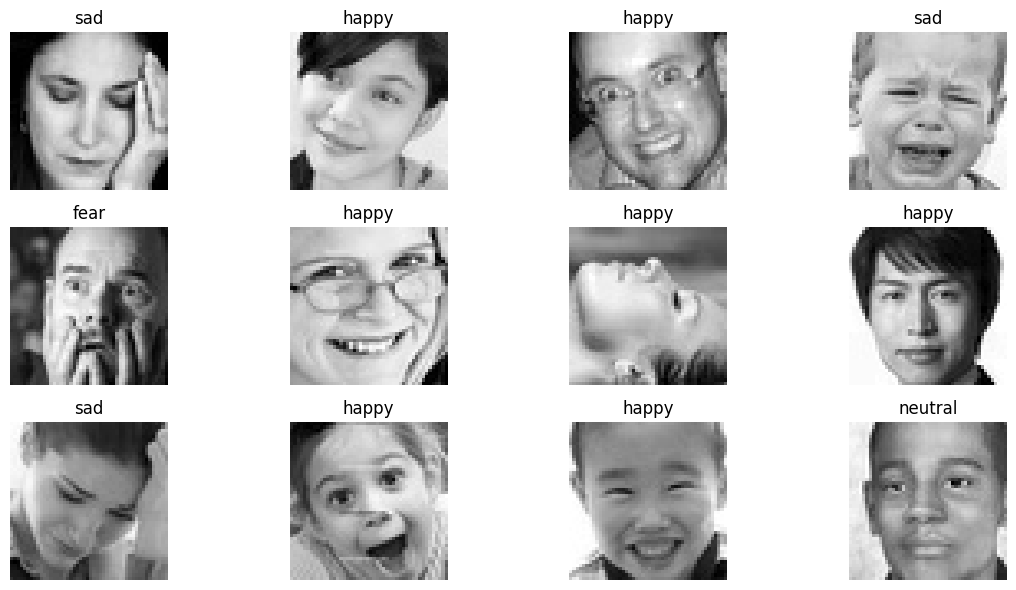

In [ ]:
plt.figure(figsize=(12, 6))

for images, labels in train_ds.take(1):
    for i in range(min(12, len(images))):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().squeeze(), cmap="gray")
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def normalize_images(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels

train_ds = train_ds.map(
    normalize_images, num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

val_ds = val_ds.map(
    normalize_images, num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

test_ds = test_ds.map(
    normalize_images, num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(48, 48, 1)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(len(class_names), activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,527 (2.61 MB)

 Trainable params: 683,527 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_facial_expression.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 141s 388ms/step - accuracy: 0.3073 - loss: 1.7254 - val_accuracy: 0.4099 - val_loss: 1.5593
Epoch 2/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 129s 358ms/step - accuracy: 0.4138 - loss: 1.5188 - val_accuracy: 0.4506 - val_loss: 1.4349
Epoch 3/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 128s 356ms/step - accuracy: 0.4646 - loss: 1.3963 - val_accuracy: 0.4935 - val_loss: 1.3365
Epoch 4/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 129s 359ms/step - accuracy: 0.4996 - loss: 1.3100 - val_accuracy: 0.5130 - val_loss: 1.2805
Epoch 5/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 141s 357ms/step - accuracy: 0.5313 - loss: 1.2372 - val_accuracy: 0.5280 - val_loss: 1.2422
Epoch 6/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 143s 359ms/step - accuracy: 0.5596 - loss: 1.1680 - val_accuracy: 0.5309 - val_loss: 1.2380
Epoch 7/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 126s 352ms/step - accuracy: 0.5809 - loss: 1.1127 - val_accuracy: 0.5358 - val_loss: 1.2525
Epoch 8/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 126s 352ms/step - accuracy: 0.6055 -

In [ ]:
import matplotlib.pyplot as plt

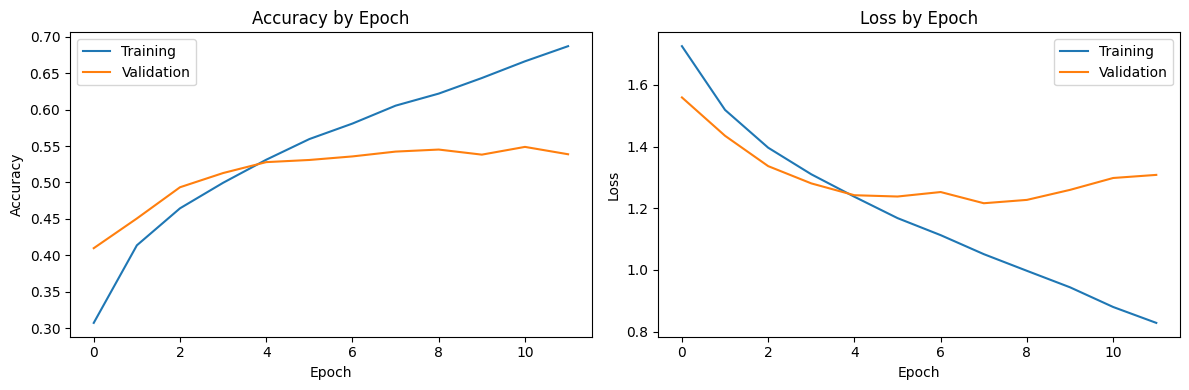

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy by Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss by Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

model = tf.keras.models.load_model("best_facial_expression.keras")

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy (%): {test_accuracy * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")

113/113 ━━━━━━━━━━━━━━━━━━━━ 20s 174ms/step - accuracy: 0.5428 - loss: 1.2102
Test accuracy: 0.5428
Test accuracy (%): 54.28%
Test loss: 1.2102


113/113 ━━━━━━━━━━━━━━━━━━━━ 15s 131ms/step
              precision    recall  f1-score   support

       angry       0.43      0.48      0.45       958
     disgust       0.92      0.11      0.19       111
        fear       0.36      0.34      0.35      1024
       happy       0.76      0.77      0.77      1774
     neutral       0.48      0.57      0.52      1233
         sad       0.42      0.35      0.38      1247
    surprise       0.71      0.67      0.69       831

    accuracy                           0.54      7178
   macro avg       0.58      0.47      0.48      7178
weighted avg       0.55      0.54      0.54      7178



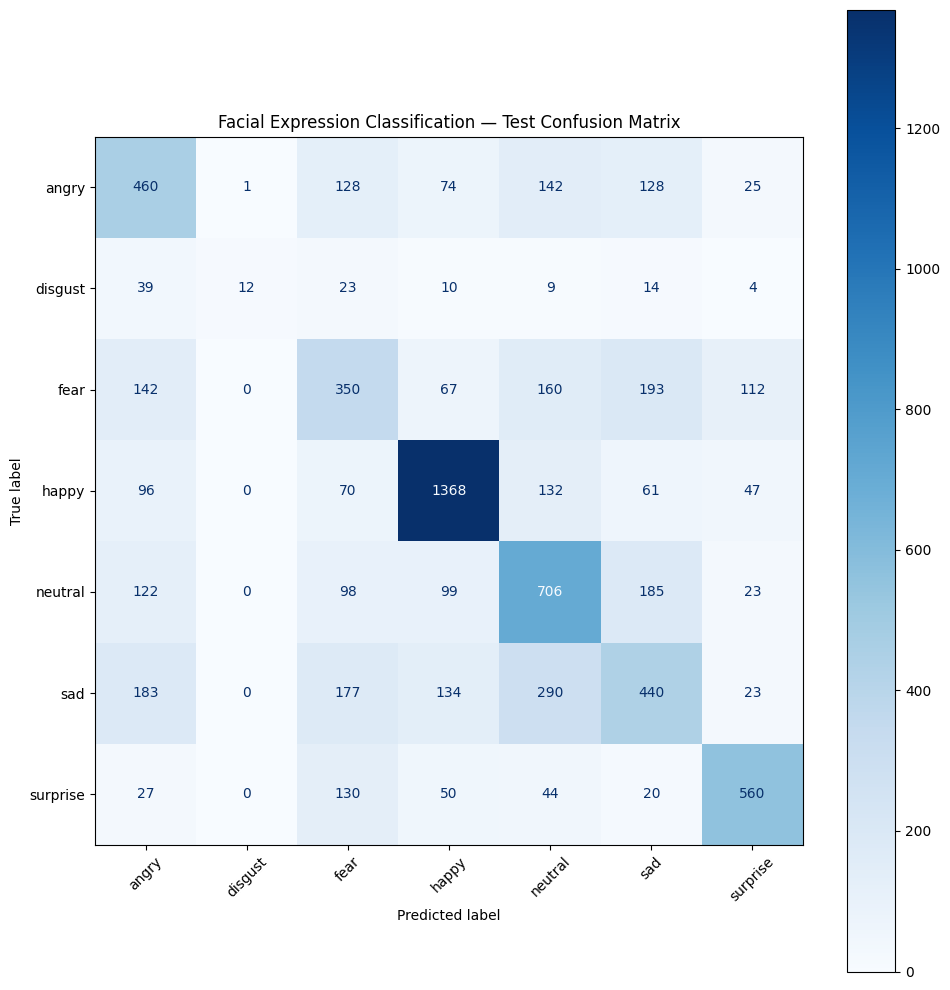

In [ ]:
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Facial Expression Classification — Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
import json

model.save("facial_expression_model.keras")

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

print("Model and class labels saved.")

Model and class labels saved.


In [ ]:
model.save("facial_expression_model.keras")

import json

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

print("Both files saved successfully!")

Both files saved successfully!


In [20]:
from google.colab import files

files.download("facial_expression_model.keras")
files.download("class_names.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>